## Computing ROC scores

Load experimental data. Data is post-processed, i.e. with recall/precision and other metrics computed.

In [153]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
print(statdata.shape)
statdata.head()

(750983, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,0.888889
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,0.833333
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,0.944444
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000


Pick 1 dataset and 1 ranking method as an example.

In [169]:
subset = statdata[
          (statdata['ranking_method'] == 'ExtraTrees')
        & (statdata['description'] == 'Total # of Features [p=10000,n=1600,p_=2,h=0.4,edm=Easy]')
]
subset.shape

(102216, 11)

Add points (fpr=0, recall=0) and (fpr=1, recall=1) manually to every replica.

In [170]:
subset_ = subset.copy()
for key, data in subset.groupby([ 'description', 'ranking_method', 'replica_no' ]):
    description, ranking_method, replica_no = key
    subset_ = subset_.append(pd.DataFrame(data={
        'description': description,
        'ranking_method': ranking_method,
        'replica_no': replica_no,
        'fpr': [0, 1],
        'recall': [0, 1]
    }))
print(subset.shape)
print(subset_.shape)
print('added {} points'.format(len(subset_) - len(subset)))

(102216, 11)
(102264, 11)
added 48 points


Plot fpr/recall for 1 replica.

Text(0.5, 1.0, 'auc = 0.5741108685868587')

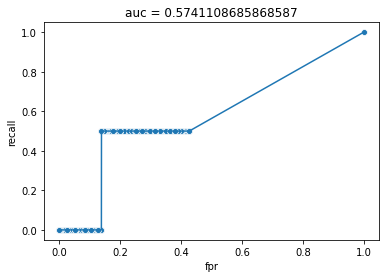

In [171]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

replica = subset_[subset_['replica_no'] == 4]
g = sns.scatterplot(data=replica, x='fpr', y='recall')
g = sns.lineplot(data=replica, x='fpr', y='recall')

# auc
auc = np.trapz(replica.sort_values('fpr').recall.values,\
               replica.sort_values('fpr').fpr.values)
plt.title('auc = {}'.format(auc))

Show curves for **all** replicas

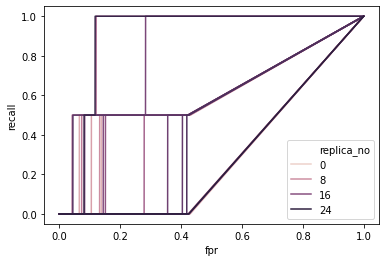

In [172]:
import seaborn as sns

g = sns.lineplot(data=subset_, x='fpr', y='recall', estimator=None, hue='replica_no')

Plot average fpr/recall of replicas.

Text(0.5, 1.0, 'auc = 0.5966910018599106')

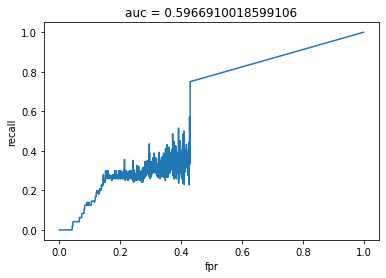

In [173]:
res = subset_.groupby([ 'description', 'ranking_method', 'feature_rank' ])\
             .agg({ 'recall': 'mean', 'fpr': 'mean' }).reset_index()
res = res.append(pd.DataFrame(data={ 'fpr': [0, 1], 'recall': [0, 1] }))
g = sns.lineplot(data=res, x='fpr', y='recall')

# auc
auc = np.trapz(res.sort_values('fpr').recall.values,\
               res.sort_values('fpr').fpr.values)
plt.title('auc = {}'.format(auc))

Compute average tpr/fpr

-> using [https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc_crossval.html](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc_crossval.html) as a reference.

Text(0.5, 1.0, 'auc = 0.4906379890637452')

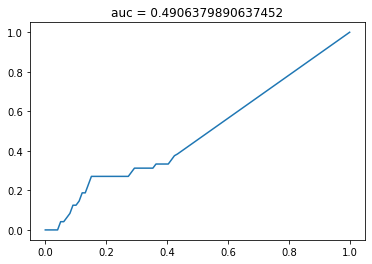

In [174]:

# compute mean tpr by interpolation
tprs = []
mean_fpr = np.linspace(0, 1, 100)
for key, data in subset_.groupby([ 'description', 'ranking_method', 'replica_no' ]):
    fpr = data.sort_values('fpr').fpr.values
    tpr = data.sort_values('fpr').recall.values
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0

g = sns.lineplot(data={ 'fpr': mean_fpr, 'recall': mean_tpr }, x='fpr', y='recall')
auc = np.trapz(mean_tpr, mean_fpr)
plt.title('auc = {}'.format(auc))